<a name="top" id="top"></a>

<div align="center">

<h1>PSO 9 — Exercise 2: PID control of a process with delay <em>(Bode tutorial 4 of 4)</em></h1>

<p>
  <a href="https://colab.research.google.com/github/SECQUOIA/PU_CHE456_F2026/blob/main/PSO9/PSO9_2_PIDClosedLoopWithDelay.ipynb" target="_parent">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab">
  </a>
  <a href="https://secquoia.github.io/">
    <img src="https://img.shields.io/badge/🌲⚛️🌐-SECQUOIA-blue" alt="SECQUOIA">
  </a>
</p>

</div>


**Before starting:** complete the PID-control lectures and PSO 9 Exercise 1. This self-directed exercise follows those prerequisites; the early release is for access and preview. Bring questions to the next supported PSO. Check Brightspace for the current submission deadline.


## Notation used in this notebook

$\bar y$ is a fixed reference steady state, $y'(t)=y(t)-\bar y$ is a deviation,
and $\dfrac{dy'}{dt}$ is its time derivative. A prime never means a derivative.
Because the reference is constant, $\dfrac{dy'}{dt}=\dfrac{dy}{dt}$.
Zero initial state deviations mean that the model starts at its reference
equilibrium before the input event; changing coordinates alone does not ensure this.

For transfer-function simulations, $U(s)=\mathcal L[u'(t)]$ and
$Y(s)=\mathcal L[y'(t)]$. Python arrays named `u`, `y`, `y_out`, or similar store
deviations in these simulations. Their plotted final value is $y'(\infty)$,
when that limit exists. Restore $y(\infty)=\bar y+y'(\infty)$ for a physical
prediction; do not rename the new final value $\bar y$.

For feedback models, $Y_{sp}(s)=\mathcal L[y_{sp}'(t)]$ and
$D(s)=\mathcal L[d'(t)]$ describe set-point and disturbance changes. Read a
unit set-point step as a one-unit change from the reference, with the signal
scaling stated in the model. The course controller symbols are $K_c$, $\tau_I$,
and $\tau_D$; code names `Kp`, `Ti`, and `Td` denote these same settings where
used. Code names `Ku` and `Tu` denote ultimate gain $K_{cu}$ and period $P_u$.


## A heated tank followed by a transport pipe

Use the perfectly mixed heated tank derived in Exercise 1. With volume $V$,
constant volumetric flow $q$, density $\rho$, heat capacity $C_p$, fixed inlet
temperature $T_i$, tank/outlet temperature $T_h$ and heater duty $Q$, its
energy balance is

$$\rho V C_p\dfrac{dT_h}{dt}=\rho q C_p(T_i-T_h)+Q.$$

Subtract the reference steady state. Use fixed positive temperature and heat-rate
scales $T_s$ and $Q_s$: $x'=\dfrac{T_h'}{T_s}$ and $u'=\dfrac{Q'}{Q_s}$.
Then

$$\dfrac{V}{q}\dfrac{dx'}{dt}+x'
=\dfrac{Q_s}{\rho q C_pT_s}u'.$$

The illustrative choices $\dfrac{V}{q}=5$ s and
$\dfrac{Q_s}{\rho q C_pT_s}=2$ give $5\dfrac{dx'}{dt}+x'=2u'$.
The tank outlet travels through an insulated pipe of volume $V_{pipe}$.
Assume plug flow at constant $q$, with no heat loss or axial dispersion, and
choose $\theta=\dfrac{V_{pipe}}{q}=1$ s. Let $T_{out}$ be the temperature at
the downstream sensor. With negligible sensor dynamics, its scaled deviation
is $y'=\dfrac{T_{out}'}{T_s}=x'(t-1)$.
With zero initial state deviations and reference prehistory,

$$G(s)=\dfrac{Y(s)}{U(s)}=\dfrac{2e^{-s}}{5s+1}.$$

Thermal storage causes gradual change in the tank; transport delays that change
at the sensor by 1 s. Assume small deviations, constant properties, and unity
actuator/measurement scaling. The set point shares the measured temperature
scale. Delay adds phase lag and reduces stability margin. A Padé curve can move
before 1 s; this is an approximation artifact rather than physical transport.


**Topic:** Compare P, PI, and PID control for a first-order process with time delay.

This exercise connects open-loop frequency-domain measures to closed-loop behavior. You will see why integral action removes offset, why delay reduces the available stability margin, and why derivative action must be filtered.


## 1. Delayed process

Use $G(s)=\dfrac{2e^{-s}}{5s+1}$. The simulation replaces the one-second delay
by the first-order Padé approximation

$$e^{-s}\approx\dfrac{1-\dfrac{s}{2}}{1+\dfrac{s}{2}},\qquad
G_{Pade}(s)=\dfrac{-2s+4}{5s^2+11s+2}.$$

It is useful near crossover, but does not reproduce the exact transport delay
at every frequency or time. For these settings it overstates gain margin:
the exact-delay margins are about 2.83 (P), 2.55 (PI) and 2.56 (PID), compared
with 3.67, 3.24 and 3.12 from first-order Padé. Phase margins differ by about
0.8–1.1 degrees. Validate a final design against the actual delay.


## Predict the P-controller response

The negative-feedback relation from Topic 11 follows directly from the
signals in this loop. Let $E(s)$ and $P(s)$ be the transforms of the error
and controller-output deviations. The temperature set point and measurement
share a scale, and unity actuator scaling gives $U(s)=P(s)$. Therefore

$$E(s)=Y_{sp}(s)-Y(s),\qquad
P(s)=G_c(s)E(s),\qquad Y(s)=G(s)U(s).$$

Substitution gives $Y=G_cG(Y_{sp}-Y)$. Defining the open-loop transfer function
$L(s)=G_c(s)G(s)$ and collecting the terms in $Y$ yields

$$\dfrac{Y(s)}{Y_{sp}(s)}=\dfrac{L(s)}{1+L(s)}.$$

For a stable closed loop with finite $L(0)$, a unit set-point step has final
output deviation $\dfrac{L(0)}{1+L(0)}$ and offset
$1-\dfrac{L(0)}{1+L(0)}$. For P control, substitute the supplied Padé process
and $K_c=1.5$: the characteristic polynomial is $5s^2+8s+8$.
Its roots must have negative real parts before its DC gain can be used as a
final value. This polynomial checks the Padé model; the frequency margins
above also check the loop with the exact delay.

Before running the P, PI and PID comparison, spend about 3 minutes applying
this relation:

1. For P control, use $K_c=1.5$ and $G(0)=2$ to calculate the unit-step final
   value and offset.
2. Compare your prediction with the printed P final value. If they differ,
   check the feedback sign, signal scaling and denominator.

The labeled exercise below compares IAE, overshoot and margins to support
a controller choice.

Keep the hand calculation with your notebook work; no separate report is required.


In [11]:
# If using this notebook in Google Colab, install python-control
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %pip install -q control==0.10.2

In [12]:
# Imports and plotting defaults
import numpy as np
import matplotlib.pyplot as plt
import control as ct
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 4)


In [13]:
# Delayed plant and matched controller settings
s = ct.tf([1, 0], [1])
delay_num, delay_den = ct.pade(1.0, 1)
G = (2 / (5*s + 1)) * ct.tf(delay_num, delay_den)

Kp, Ti, Td, N = 1.5, 4.0, 0.5, 10.0
controllers = {
    'P': Kp,
    'PI': Kp * (1 + 1/(Ti*s)),
    'PID': Kp * (1 + 1/(Ti*s) + (Td*s)/(1 + Td*s/N)),
}

print('Padé model of the delayed plant:')
print(G)


Padé model of the delayed plant:
<TransferFunction>: sys[66]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

      -2 s + 4
  ----------------
  5 s^2 + 11 s + 2


In [14]:
# Compare stability margins of the three open loops
print(f"{'Mode':<5} {'Gain margin':>13} {'Phase margin (deg)':>20} {'Gain crossover (rad/s)':>25}")
for name, controller in controllers.items():
    gain_margin, phase_margin, _phase_cross, gain_cross = ct.margin(controller * G)
    print(f'{name:<5} {gain_margin:>13.2f} {phase_margin:>20.1f} {gain_cross:>25.3f}')


Mode    Gain margin   Phase margin (deg)    Gain crossover (rad/s)
P              3.67                 77.9                     0.566
PI             3.24                 51.7                     0.616
PID            3.12                 68.7                     0.578


P: final value = 0.750
PI: final value = 1.000
PID: final value = 1.000


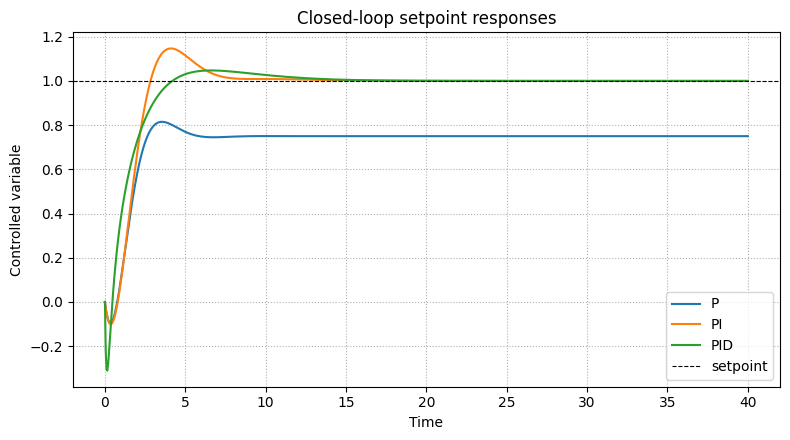

In [15]:
# Compare closed-loop unit-step setpoint responses
t = np.linspace(0, 40, 800)
responses = {}

plt.figure(figsize=(8, 4.5))
for name, controller in controllers.items():
    closed_loop = ct.feedback(controller * G, 1)
    time, output = ct.step_response(closed_loop, t)
    responses[name] = (time, output, closed_loop)
    plt.plot(time, output, label=name)

plt.axhline(1, color='k', linewidth=0.8, linestyle='--', label='setpoint')
plt.xlabel('Time')
plt.ylabel('Controlled variable')
plt.title('Closed-loop setpoint responses')
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()

for name, (_time, _output, closed_loop) in responses.items():
    print(f'{name}: final value = {ct.dcgain(closed_loop):.3f}')


## 2. Interpret the comparison

- **P control** leaves offset because the loop gain at zero frequency is finite.
- **PI and PID control** have infinite DC loop gain and therefore reach the unit setpoint in this ideal model.
- **Delay** contributes phase lag without reducing magnitude, so it limits how aggressively any controller can be tuned.
- **Filtered derivative action** may improve phase margin and damping, but it should act on the measured variable in practice to avoid derivative kick and must be checked against measurement noise and actuator limits.


## Exercise — quantify performance and robustness

For each controller, calculate integral absolute error (IAE), peak overshoot relative to that loop's own steady-state value, and phase margin. Decide which controller gives the best compromise for this model. Do not choose only from the response speed: offset, robustness, actuator limits, and noise sensitivity also matter.


In [18]:
# Calculate IAE, overshoot, and phase margin for each controller.
for name, (_time, _output, closed_loop) in responses.items():
  IAE = np.trapezoid(np.abs(1- output), time)

  peak = np.max(output)
  final = ct.dcgain(closed_loop)

  overshoot = max(0, (peak - final) / abs(final)) *100

  _gm, phase_margin, _phase_cross, _gain_cross = ct.margin(controllers[name]*G)


  print(f'{name:<8} {IAE:>10.3f} {overshoot:>12.3f} {phase_margin:>15.3f}')

P             1.916       39.649          77.885
PI            1.916        4.737          51.666
PID           1.916        4.737          68.740


In [20]:
# State and justify your preferred controller.
'''
The PID controller is prefered. Both it and the PI controller have low
overshoot, however the PID controller provides better stability, as seen in
the phase margin value, than the PI controller. '''

'\nThe PID controller is prefered. Both it and the PI controller have low \novershoot, however the PID controller provides better stability, as seen in \nthe phase margin value, than the PI controller. '